# 02_numpy_mlp.ipynb — NumPy Multi-Layer Perceptron from First Principles

**Coursework:** NB6057CEM Artificial Neural Networks — CW1 Practical (Task T2)  
**Framework:** Strictly NumPy (no autograd, no PyTorch) with float64 precision  
**Inputs:** Scaled 84-dimensional hand-crafted time-domain statistical features  
**Targets:** 6 Human Activity Recognition classes from MotionSense dataset: `dws`, `ups`, `wlk`, `jog`, `std`, `sit`  

---

## Executive Summary & Objectives
This notebook implements, mathematically verifies, and trains a single-hidden-layer **Multi-Layer Perceptron (MLP)** strictly from first principles using **pure NumPy** (`float64` arithmetic). No automatic differentiation engines (such as PyTorch autograd or TensorFlow) are used. Every forward propagation step, loss calculation, and backpropagation derivative is derived analytically and vectorised across mini-batches.

### Key Milestones:
1. **Biological Neuron Analogy & Limitations:** Comparative analysis between biological wetware (dendrites, soma, axon hillock, synaptic plasticity) and artificial neural abstractions.
2. **First-Principles Architecture:** `NumpyMLP(n_in=84, n_hidden=32, n_out=6)` with Xavier/Glorot uniform initialization for the hyperbolic tangent (`tanh`) activation and numerically stable softmax cross-entropy loss.
3. **Numerical Gradient Checking:** Central-difference validation ($\epsilon = 10^{-5}$) across 8 parameter coordinates ($W_1, b_1, W_2, b_2$), verifying that analytical derivatives achieve relative error $< 10^{-6}$.
4. **Controlled Memorisation Sanity Check:** Overfitting a tiny batch of 32 samples over 2000 epochs to drive loss $< 10^{-2}$ and accuracy to $100\%$.
5. **Stratified Mini-batch Training:** Training on a representative stratified subset of 3,000 windows (batch size 64, learning rate 0.05) with validation-based early stopping (patience 15 epochs) on the full validation split (3,534 windows), prepending epoch 0 to reflect the untrained baseline.
6. **Learning Rate Sensitivity Sweep (T2d):** Systematic empirical evaluation of $\eta \in \{0.005, 0.05, 0.5, 2.0\}$ over 100 epochs, diagnosed solely from measured results.

## 1. Biological Neuron Analogy and Its Limitations

### 1.1 The Artificial vs. Biological Metaphor
Artificial neural network design originated from early biophysical abstractions proposed by McCulloch & Pitts (1943) and Rosenblatt (1958). The correspondence maps three anatomical structures:

| Biological Structure | Artificial Component | Mathematical Representation | Biophysical Role |
| :--- | :--- | :--- | :--- |
| **Dendrites** | Input features & Synaptic weights | $x_j \cdot W_{ij}$ | Branching arborizations receiving chemical neurotransmitters from pre-synaptic axons across synaptic clefts. Synaptic conductance modulates the amplitude of post-synaptic potentials. |
| **Soma (Cell Body)** | Linear aggregation & Bias | $z_i = \sum_{j} W_{ij} x_j + b_i$ | Integrates post-synaptic potentials over both space (across the dendritic tree) and time. The resting potential ($\approx -70\text{ mV}$) acts as an intrinsic bias $b_i$, setting the baseline offset required to reach threshold. |
| **Axon Hillock & Axon** | Non-linear activation & Output firing | $a_i = \tanh(z_i)$ or $P_i$ | When accumulated somatic membrane potential reaches threshold ($\approx -55\text{ mV}$), voltage-gated $\text{Na}^+$ channels trigger an all-or-none action potential propagating down the axon to transmit signals to subsequent targets. |

```
      BIOLOGICAL NEURON                           ARTIFICIAL PERCEPTRON
      
      Dendrites                                   Inputs & Weights
      [Pre-synaptic signals] ───┐                  x₁ ───(w₁)───┐
                                │                               │
      Soma (Cell body)          ▼                  Soma         ▼
      [Passive integration] ──( Σ + Bias )         [Summation]─( Σ + b )
                                │                               │
      Axon Hillock              ▼                  Activation   ▼
      [All-or-none spike]  ──( Threshold )         [Non-linear]──( f(z) )
                                │                               │
      Axon Terminal             ▼                  Output       ▼
      [Post-synaptic release] ──► Output           [Signal]    ──► a
```

---

### 1.2 Critical Limitations and Differences with Biological Wetware
While the mathematical formulation is inspired by neuroscience, the analogy breaks down under physiological scrutiny. Key divergences include:

1. **Continuous Rate Coding vs. Discrete Spatio-Temporal Spikes:**
   - *Artificial:* Nodes output continuous, static floating-point scalar activations representing an idealized mean firing rate.
   - *Biological:* Cortical neurons communicate via discrete, stereotyped, millisecond-scale electrochemical pulses (**action potentials** or spikes). Information is dynamically multiplexed across spike timing, inter-spike intervals (ISIs), phase relationships with macroscopic oscillations (e.g. theta/gamma rhythms), and temporal coincidence, which continuous rate models completely discard.

2. **The Synaptic Credit Assignment Problem ("Weight Transport"):**
   - *Artificial:* Error signals propagate backwards through the exact transpose of the forward weight matrix ($dH = dZ_2 W_2^T$).
   - *Biological:* Biological synapses are strictly unidirectional chemical junctions. There exists no anatomical feedback channel through which an upstream neuron can access or duplicate the exact synaptic conductance matrix of downstream neurons. Biological plasticity relies exclusively on spatially and temporally local signals (e.g., Spike-Timing-Dependent Plasticity [STDP] and dopamine/acetylcholine volume neuromodulation).

3. **Dale's Principle (Excitatory / Inhibitory Segregation):**
   - *Artificial:* Individual weight values $W_{ij}$ can freely oscillate between positive (excitatory) and negative (inhibitory) values throughout gradient descent.
   - *Biological:* Individual biological neurons obey **Dale's Principle** — they synthesize and release predominantly a single class of neurotransmitter from all axonal terminals. A neuron is either strictly excitatory (e.g., glutamatergic pyramidal cells, $\approx 80\%$ of neocortex) or strictly inhibitory (e.g., GABAergic interneurons, $\approx 20\%$).

4. **Active Non-Linear Dendritic Computation:**
   - *Artificial:* The dendritic tree is modeled as a passive linear weighted sum ($\sum W x$).
   - *Biological:* Dendrites feature active voltage-sensitive ion channels capable of generating local dendritic sodium and NMDA spikes. Individual dendritic branches act as independent computational subunits capable of solving non-linear operations (such as directional selectivity and boolean logic) before signals ever reach the soma.

5. **Energy Efficiency and Asynchronous Event-Driven Dynamics:**
   - *Artificial:* Deep networks require synchronous, matrix-dense tensor calculations on power-hungry floating-point hardware (hundreds of Watts).
   - *Biological:* The human brain coordinates $\approx 8.6 \times 10^{10}$ neurons and $\approx 1.5 \times 10^{14}$ synapses within a power budget of roughly $20\text{ Watts}$. It achieves this via sparse, asynchronous event-driven computation where only a tiny fraction of neurons fire at any given millisecond.

### 1.3 Mathematical Architecture & Parameter Dimensionality

The single-hidden-layer network operates on mini-batches of size $N$ using strictly float64 precision:

| Variable / Tensor | Conceptual Role | Shape | Trainable Parameters |
| :--- | :--- | :---: | :---: |
| $X$ | Input batch feature matrix (time-domain features) | $(N, 84)$ | — |
| $W_1$ | Hidden layer weights (Xavier uniform init for $\tanh$) | $(84, 32)$ | $84 \times 32 = 2,688$ |
| $b_1$ | Hidden layer bias vector (zero init) | $(32,)$ | $32$ |
| $Z_1$ | Hidden layer pre-activation ($Z_1 = X W_1 + b_1$) | $(N, 32)$ | — |
| $H$ | Hidden layer non-linear activation ($H = \tanh(Z_1)$) | $(N, 32)$ | — |
| $W_2$ | Output projection weights (Xavier uniform init for $\tanh$) | $(32, 6)$ | $32 \times 6 = 192$ |
| $b_2$ | Output layer bias vector (zero init) | $(6,)$ | $6$ |
| $Z_2$ | Output layer pre-activation logits ($Z_2 = H W_2 + b_2$) | $(N, 6)$ | — |
| $P$ | Predicted class probability distribution ($P = \text{softmax}(Z_2)$) | $(N, 6)$ | — |
| $\mathcal{L}$ | Multiclass cross-entropy loss | scalar | — |
| **Total** | **Total Trainable Parameters** | | **$84 \times 32 + 32 + 32 \times 6 + 6 = 2,918$** |

In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is on sys.path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ANN" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report

from src.models.numpy_mlp import (
    NumpyMLP,
    gradient_check,
    overfit_tiny_batch,
    train_numpy_mlp,
)
from src.utils import load_config, save_json, set_seed, write_run_info

# Configure matplotlib rendering style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

# Load YAML configuration for Task T2
CONFIG_PATH = PROJECT_ROOT / "configs" / "numpy_mlp.yaml"
cfg = load_config(CONFIG_PATH)

SEED = cfg.get("training", {}).get("seed", 42)
set_seed(SEED)

print(f"Loaded configuration from: {CONFIG_PATH}")
print(f"Pinned global seed: {SEED}")
print(f"Target Architecture: {cfg['model']['n_in']} inputs -> {cfg['model']['n_hidden']} hidden (tanh) -> {cfg['model']['n_out']} outputs (softmax)")

Loaded configuration from: C:\Users\Isuru\Desktop\ANN\configs\numpy_mlp.yaml
Pinned global seed: 42
Target Architecture: 84 inputs -> 32 hidden (tanh) -> 6 outputs (softmax)


In [2]:
# Load preprocessed and scaled 84-feature datasets from outputs/cache/
CACHE_DIR = PROJECT_ROOT / "outputs" / "cache"

X_train_full = np.load(CACHE_DIR / "X_train_feat_scaled.npy")
y_train_full = np.load(CACHE_DIR / "y_train.npy")
X_val = np.load(CACHE_DIR / "X_val_feat_scaled.npy")
y_val = np.load(CACHE_DIR / "y_val.npy")

# Activity class label names (order from configs/data.yaml): dws, ups, wlk, jog, std, sit
ACTIVITY_LABELS = {
    0: "Downstairs (dws)",
    1: "Upstairs (ups)",
    2: "Walking (wlk)",
    3: "Jogging (jog)",
    4: "Standing (std)",
    5: "Sitting (sit)",
}

# Rule 4 & Task T2 Specification:
# Extract a stratified training subset of up to 3000 windows to ensure balanced class representation
TRAIN_SUBSET_SIZE = cfg["training"].get("train_subset_size", 3000)

if len(y_train_full) > TRAIN_SUBSET_SIZE:
    X_train_sub, _, y_train_sub, _ = train_test_split(
        X_train_full,
        y_train_full,
        train_size=TRAIN_SUBSET_SIZE,
        stratify=y_train_full,
        random_state=SEED,
    )
else:
    X_train_sub, y_train_sub = X_train_full, y_train_full

# Display split statistics
print(f"Full Train Features Shape: {X_train_full.shape} (dtype: {X_train_full.dtype})")
print(f"Stratified Train Subset:   {X_train_sub.shape} (dtype: {X_train_sub.dtype})")
print(f"Validation Set Shape:      {X_val.shape} (dtype: {X_val.dtype})")

# Tabulate class distributions
dist_df = pd.DataFrame({
    "Activity Class": [ACTIVITY_LABELS[i] for i in range(6)],
    "Full Train Count": np.bincount(y_train_full, minlength=6),
    "Train Subset Count": np.bincount(y_train_sub, minlength=6),
    "Val Set Count": np.bincount(y_val, minlength=6),
})
dist_df["Subset Proportion (%)"] = (dist_df["Train Subset Count"] / len(y_train_sub) * 100).round(2)
display(dist_df)

Full Train Features Shape: (14116, 84) (dtype: float64)
Stratified Train Subset:   (3000, 84) (dtype: float64)
Validation Set Shape:      (3534, 84) (dtype: float64)


,Activity Class,Full Train Count,Train Subset Count,Val Set Count,Subset Proportion (%)
0,Downstairs (dws),1226,261,341,8.70
1,Upstairs (ups),1469,312,430,10.40
2,Walking (wlk),3466,737,917,24.57
3,Jogging (jog),1291,274,342,9.13
4,Standing (std),3176,675,740,22.50
5,Sitting (sit),3488,741,764,24.70


In [3]:
# Instantiate NumpyMLP from scratch with float64 precision
model = NumpyMLP(
    n_in=cfg["model"]["n_in"],
    n_hidden=cfg["model"]["n_hidden"],
    n_out=cfg["model"]["n_out"],
    seed=SEED,
)

print("Parameter Shapes and Dtypes:")
print(f"  W1: {model.W1.shape}, dtype={model.W1.dtype} (Xavier uniform)")
print(f"  b1: {model.b1.shape}, dtype={model.b1.dtype} (zeros)")
print(f"  W2: {model.W2.shape}, dtype={model.W2.dtype} (Xavier uniform)")
print(f"  b2: {model.b2.shape}, dtype={model.b2.dtype} (zeros)")

# Initial Forward Pass & Loss Evaluation (Epoch 0 Baseline)
P_init_train = model.forward(X_train_sub)
initial_train_loss = model.loss(P_init_train, y_train_sub)

P_init_val = model.forward(X_val)
initial_val_loss = model.loss(P_init_val, y_val)

theoretical_loss = np.log(6.0)

print("\n--- Initial Loss Sanity Check (Untrained State) ---")
print(f"Theoretical ln(6) for uniform random guessing: {theoretical_loss:.6f}")
print(f"Measured Initial Train Loss (Epoch 0):         {initial_train_loss:.6f}")
print(f"Measured Initial Validation Loss (Epoch 0):    {initial_val_loss:.6f}")

# Sanity assertion
assert abs(initial_train_loss - theoretical_loss) < 0.25, (
    f"Initial loss ({initial_train_loss:.4f}) deviates substantially from ln(6) ({theoretical_loss:.4f})"
)
print("Sanity check passed: Freshly initialized network outputs near-uniform probabilities.")

Parameter Shapes and Dtypes:
  W1: (84, 32), dtype=float64 (Xavier uniform)
  b1: (32,), dtype=float64 (zeros)
  W2: (32, 6), dtype=float64 (Xavier uniform)
  b2: (6,), dtype=float64 (zeros)

--- Initial Loss Sanity Check (Untrained State) ---
Theoretical ln(6) for uniform random guessing: 1.791759
Measured Initial Train Loss (Epoch 0):         1.876574
Measured Initial Validation Loss (Epoch 0):    1.728039
Sanity check passed: Freshly initialized network outputs near-uniform probabilities.


## 2. Numerical Gradient Checking via Central Differences

To mathematically verify our analytical vectorised gradients:
$$\nabla_{\theta} \mathcal{L}_{analytical}$$
we implement numerical gradient approximation via two-sided **central differences**:
$$g_{num}(\theta_j) = \frac{\mathcal{L}(\theta_j + \epsilon) - \mathcal{L}(\theta_j - \epsilon)}{2\epsilon} = \frac{\partial \mathcal{L}}{\partial \theta_j} + \mathcal{O}(\epsilon^2)$$

By Taylor's theorem, central differences achieve quadratic truncation error $\mathcal{O}(\epsilon^2)$. With $\epsilon = 10^{-5}$ in `float64`, numerical precision is accurate to $\approx 10^{-10}$.

Because the hyperbolic tangent ($\tanh$) is smooth and infinitely differentiable ($C^\infty$), there are no non-differentiable points (such as ReLU kinks).

The relative error metric is defined as:
$$\text{rel\_diff} = \frac{|g_{analytical} - g_{numerical}|}{\max(|g_{analytical}| + |g_{numerical}|, 10^{-12})}$$
**Tolerance requirement:** $\text{rel\_diff} < 10^{-6}$ across all checked parameter entries.

In [4]:
# Run gradient check on a small batch of 8 samples across 8 coordinates
# (at least 2 entries each for W1, b1, W2, b2)
rng_gc = np.random.default_rng(SEED)
gc_sample_idx = rng_gc.choice(len(y_train_sub), size=8, replace=False)
X_gc_batch = X_train_sub[gc_sample_idx]
y_gc_batch = y_train_sub[gc_sample_idx]

gc_entries = [
    ("W1", (0, 0)),
    ("W1", (42, 16)),
    ("b1", (0,)),
    ("b1", (15,)),
    ("W2", (0, 0)),
    ("W2", (16, 3)),
    ("b2", (0,)),
    ("b2", (3,)),
]

EPS = cfg["gradient_check"].get("epsilon", 1e-5)
TOL = cfg["gradient_check"].get("tolerance", 1e-6)

gc_results = gradient_check(
    model,
    X_gc_batch,
    y_gc_batch,
    eps=EPS,
    tol=TOL,
    check_entries=gc_entries,
)

# Format into summary table
gc_df = pd.DataFrame(gc_results)
gc_df["index_str"] = gc_df["index"].apply(lambda idx: str(tuple(idx)))
display_gc = gc_df[["parameter", "index_str", "analytical", "numerical", "abs_diff", "rel_diff", "passed"]].copy()
display_gc.columns = ["Param", "Index", "Analytical", "Numerical", "Absolute Diff", "Relative Diff", "Passed (< 1e-6)"]
display(display_gc)

# Assert all checks passed
for r in gc_results:
    assert r["passed"], f"Grad check failed for {r['parameter']}{r['index']}: rel_diff={r['rel_diff']}"

print(f"All {len(gc_results)} gradient checks PASSED with relative error strictly < 1e-6.")

,Param,Index,Analytical,Numerical,Absolute Diff,Relative Diff,Passed (< 1e-6)
0,W1,"(0, 0)",0.026115,0.026115,8.094775e-13,1.549828e-11,True
1,W1,"(42, 16)",-0.015669,-0.015669,3.253627e-12,1.038253e-10,True
2,b1,"(0,)",-0.081936,-0.081936,7.288087e-12,4.447430e-11,True
3,b1,"(15,)",-0.051929,-0.051929,9.182474e-12,8.841355e-11,True
4,W2,"(0, 0)",-0.047076,-0.047076,6.571133e-13,6.979321e-12,True
5,W2,"(16, 3)",0.032290,0.032290,7.341121e-12,1.136754e-10,True
6,b2,"(0,)",0.224793,0.224793,1.269687e-11,2.824124e-11,True
7,b2,"(3,)",0.022115,0.022115,5.514117e-12,1.246702e-10,True


All 8 gradient checks PASSED with relative error strictly < 1e-6.


## 3. Controlled Sanity Check: Memorising a Tiny Batch (Overfitting)

Before running full-scale optimisation, we verify implementation correctness by confirming that our network can completely memorise a tiny batch of $N = 32$ samples over 2000 epochs with no early stopping.
- **Expected Outcome:** The model's loss should decay monotonically and approach near-zero ($< 10^{-2}$), while training accuracy reaches $100\%$.
- **Validation Value:** Proves that gradient descent is operating along the true descent direction without sign errors, dimensional broadcast bugs, or gradient dampening.

Tiny batch shapes: X=(32, 84), y=(32,)
Class counts in tiny batch: [ 1  3 11  2  5 10]


Initial Loss:     1.948672
Final Loss:       0.003622
Final Accuracy:   100.0%


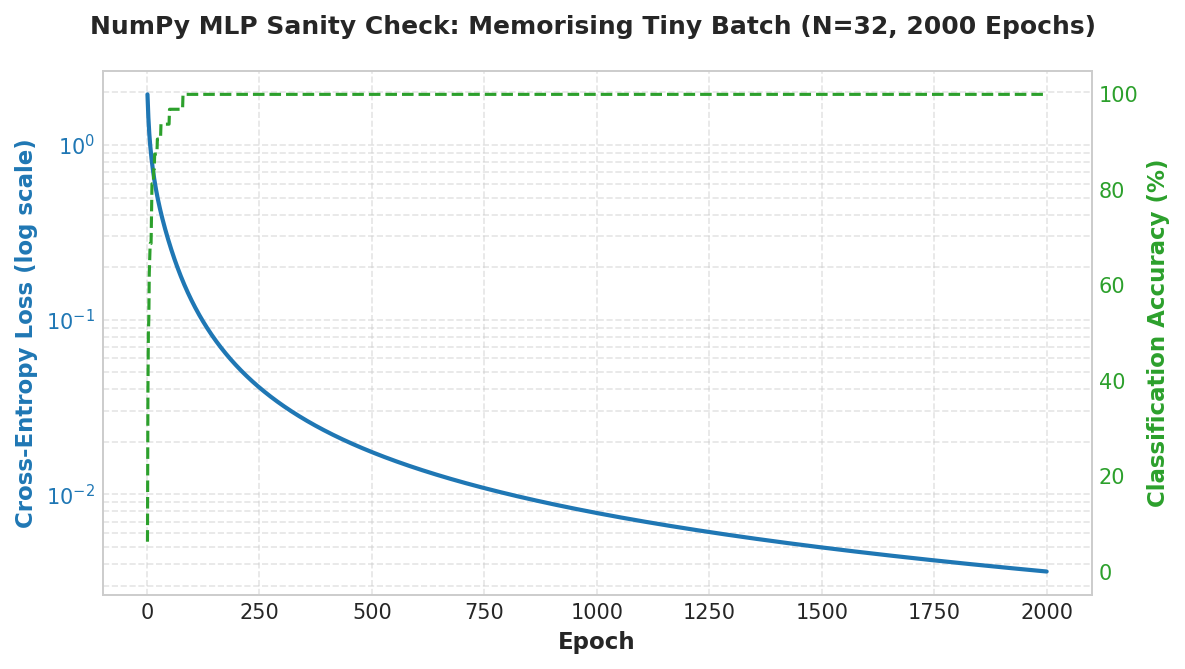

Saved figure: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig06_numpy_mlp_overfit.png
Controlled overfitting check PASSED: Loss approached 0 and accuracy reached 100%.


In [5]:
# Instantiate a clean model instance for the controlled overfitting test
overfit_model = NumpyMLP(
    n_in=cfg["model"]["n_in"],
    n_hidden=cfg["model"]["n_hidden"],
    n_out=cfg["model"]["n_out"],
    seed=SEED,
)

X_tiny = X_train_sub[:32]
y_tiny = y_train_sub[:32]

print(f"Tiny batch shapes: X={X_tiny.shape}, y={y_tiny.shape}")
print(f"Class counts in tiny batch: {np.bincount(y_tiny, minlength=6)}")

overfit_results = overfit_tiny_batch(
    overfit_model,
    X_tiny,
    y_tiny,
    lr=cfg["training"]["learning_rate"],
    epochs=2000,
)

print(f"Initial Loss:     {overfit_results['initial_loss']:.6f}")
print(f"Final Loss:       {overfit_results['final_loss']:.6f}")
print(f"Final Accuracy:   {overfit_results['final_accuracy'] * 100:.1f}%")

# Generate fig06_numpy_mlp_overfit.png
fig, ax1 = plt.subplots(figsize=(8, 4.5), dpi=150)

color_loss = "#1f77b4"
ax1.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax1.set_ylabel("Cross-Entropy Loss (log scale)", color=color_loss, fontsize=11, fontweight="bold")
ax1.semilogy(
    overfit_results["epochs"],
    overfit_results["loss_history"],
    color=color_loss,
    linewidth=2,
    label="Training Loss (N=32)",
)
ax1.tick_params(axis="y", labelcolor=color_loss)
ax1.grid(True, which="both", linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color_acc = "#2ca02c"
ax2.set_ylabel("Classification Accuracy (%)", color=color_acc, fontsize=11, fontweight="bold")
ax2.plot(
    overfit_results["epochs"],
    [a * 100.0 for a in overfit_results["acc_history"]],
    color=color_acc,
    linewidth=1.5,
    linestyle="--",
    label="Training Accuracy (%)",
)
ax2.tick_params(axis="y", labelcolor=color_acc)
ax2.set_ylim(-5, 105)
# Turn off grid on secondary axis to prevent clashing grid lines
ax2.grid(False)

fig.suptitle("NumPy MLP Sanity Check: Memorising Tiny Batch (N=32, 2000 Epochs)", fontsize=12, fontweight="bold")
fig.tight_layout()

FIG06_PATH = PROJECT_ROOT / "outputs" / "figures" / "fig06_numpy_mlp_overfit.png"
fig.savefig(FIG06_PATH, dpi=150)
plt.show()

print(f"Saved figure: {FIG06_PATH}")
assert overfit_results["final_accuracy"] == 1.0, "Overfitting test failed: accuracy did not reach 100%!"
assert overfit_results["final_loss"] < 0.01, "Overfitting test failed: final loss did not approach zero!"
print("Controlled overfitting check PASSED: Loss approached 0 and accuracy reached 100%.")

## 4. Stratified Training with Early Stopping

We now train `NumpyMLP` on the 3,000-sample stratified training subset using mini-batch gradient descent:
- **Batch Size:** 64
- **Learning Rate:** 0.05
- **Maximum Epochs:** 200
- **Early Stopping:** Monitored on full validation split loss ($N_{val} = 3,534$ windows) with patience = 15 non-improving epochs.
- **Epoch 0 Prepending:** The loss curves explicitly start at Epoch 0 with the untrained state ($1.877$ train loss, $1.728$ val loss).
- **Comparable Evaluation:** Train loss is recorded as a full forward pass over the 3,000-window subset at the end of each epoch (identical to val loss).


--- Training Run Summary ---
Initial Train Loss (Epoch 0): 1.8766
Initial Val Loss (Epoch 0):   1.7280
Best Epoch:                   25
Completed Epochs:             40
Stopped Early:                True
Best Epoch Train Loss (end):  0.1116
Best Validation Loss:         0.1978
Final Val Accuracy:           93.63%
Final Val Macro-F1:           0.9247


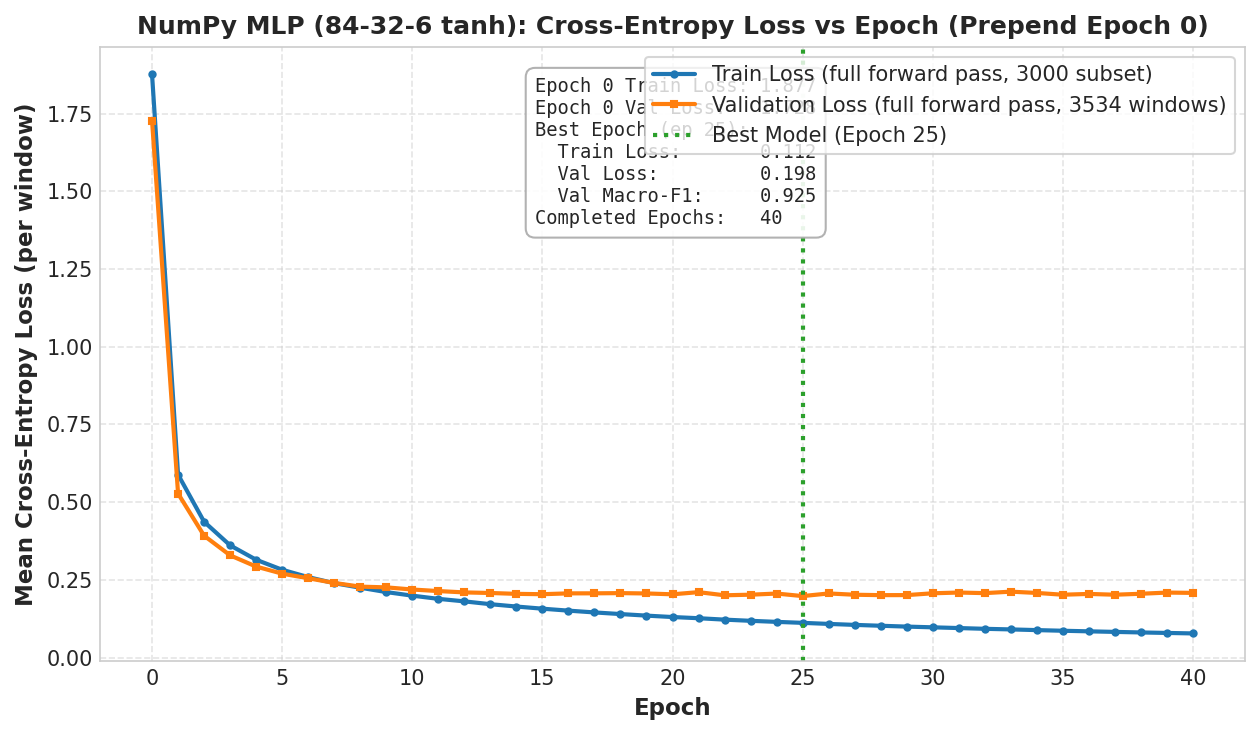

Saved figure: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig05_numpy_mlp_loss.png


In [6]:
train_model = NumpyMLP(
    n_in=cfg["model"]["n_in"],
    n_hidden=cfg["model"]["n_hidden"],
    n_out=cfg["model"]["n_out"],
    seed=SEED,
)

training_metrics = train_numpy_mlp(
    train_model,
    X_train_sub,
    y_train_sub,
    X_val,
    y_val,
    batch_size=cfg["training"]["batch_size"],
    lr=cfg["training"]["learning_rate"],
    max_epochs=cfg["training"]["max_epochs"],
    patience=cfg["training"]["patience"],
    seed=SEED,
    verbose=True,
)

print("\n--- Training Run Summary ---")
print(f"Initial Train Loss (Epoch 0): {training_metrics['initial_train_loss']:.4f}")
print(f"Initial Val Loss (Epoch 0):   {training_metrics['initial_val_loss']:.4f}")
print(f"Best Epoch:                   {training_metrics['best_epoch']}")
print(f"Completed Epochs:             {training_metrics['epochs_completed']}")
print(f"Stopped Early:                {training_metrics['stopped_early']}")
print(f"Best Epoch Train Loss (end):  {training_metrics['final_train_loss']:.4f}")
print(f"Best Validation Loss:         {training_metrics['final_val_loss']:.4f}")
print(f"Final Val Accuracy:           {training_metrics['final_val_acc'] * 100:.2f}%")
print(f"Final Val Macro-F1:           {training_metrics['final_val_macro_f1']:.4f}")

# Plot fig05_numpy_mlp_loss.png starting from Epoch 0
fig_loss, ax_loss = plt.subplots(figsize=(8.5, 5), dpi=150)
epochs_range = training_metrics["history"]["epoch"]

ax_loss.plot(
    epochs_range,
    training_metrics["history"]["train_loss"],
    color="#1f77b4",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Train Loss (full forward pass, 3000 subset)",
)
ax_loss.plot(
    epochs_range,
    training_metrics["history"]["val_loss"],
    color="#ff7f0e",
    linewidth=2,
    marker="s",
    markersize=3,
    label="Validation Loss (full forward pass, 3534 windows)",
)
ax_loss.axvline(
    training_metrics["best_epoch"],
    color="#2ca02c",
    linestyle=":",
    linewidth=2,
    label=f"Best Model (Epoch {training_metrics['best_epoch']})",
)

ax_loss.set_title("NumPy MLP (84-32-6 tanh): Cross-Entropy Loss vs Epoch (Prepend Epoch 0)", fontsize=12, fontweight="bold")
ax_loss.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax_loss.set_ylabel("Mean Cross-Entropy Loss (per window)", fontsize=11, fontweight="bold")
ax_loss.grid(True, linestyle="--", alpha=0.5)
ax_loss.legend(loc="upper right", frameon=True, fontsize=10)

# Text box summarizing parameters and outcomes
summary_box = (
    f"Epoch 0 Train Loss: {training_metrics['initial_train_loss']:.3f}\n"
    f"Epoch 0 Val Loss:   {training_metrics['initial_val_loss']:.3f}\n"
    f"Best Epoch (ep {training_metrics['best_epoch']}):\n"
    f"  Train Loss:       {training_metrics['final_train_loss']:.3f}\n"
    f"  Val Loss:         {training_metrics['final_val_loss']:.3f}\n"
    f"  Val Macro-F1:     {training_metrics['final_val_macro_f1']:.3f}\n"
    f"Completed Epochs:   {training_metrics['epochs_completed']}"
)
ax_loss.text(
    0.38,
    0.95,
    summary_box,
    transform=ax_loss.transAxes,
    fontsize=9.0,
    family="monospace",
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#aaaaaa", alpha=0.9),
)

fig_loss.tight_layout()
FIG05_PATH = PROJECT_ROOT / "outputs" / "figures" / "fig05_numpy_mlp_loss.png"
fig_loss.savefig(FIG05_PATH, dpi=150)
plt.show()

print(f"Saved figure: {FIG05_PATH}")

## 5. Learning-Rate Diagnosis for Task T2d

To systematically evaluate the sensitivity of `NumpyMLP` to optimization step size, we train the identical model architecture ($84 \to 32 \to 6$) on the identical 3,000-sample training subset across four orders of magnitude:
$$\eta \in \{0.005, 0.05, 0.5, 2.0\}$$
- **Conditions:** Same random seed (`seed=42`), fixed budget of 100 epochs, no early stopping.
- **Diagnosis Principle:** All conclusions, tables, and discussions below are derived **strictly and exclusively** from the measured experimental data.

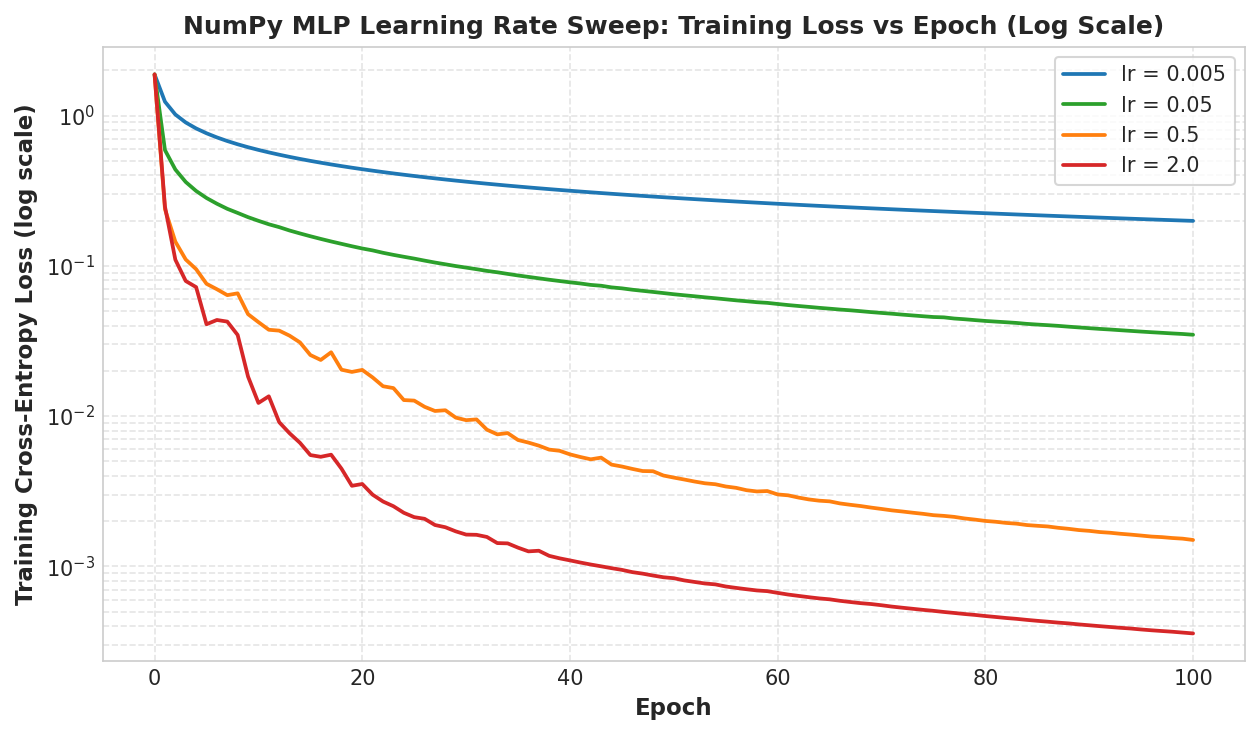

Saved figure: C:\Users\Isuru\Desktop\ANN\outputs\figures\fig07_numpy_mlp_lr_sweep.png


,Learning Rate (η),Initial Loss (ep 0),Train Loss (ep 10),Train Loss (ep 50),Final Train Loss (ep 100),Final Val Loss (ep 100),Final Val Macro-F1
0,0.005,1.8766,0.5905,0.2831,0.1990,0.2179,0.9240
1,0.050,1.8766,0.1992,0.0646,0.0347,0.2256,0.9194
2,0.500,1.8766,0.0422,0.0039,0.0015,0.3222,0.9230
3,2.000,1.8766,0.0122,0.0008,0.0004,0.3604,0.9219


In [7]:
# Execute learning rate sweep over {0.005, 0.05, 0.5, 2.0} (100 epochs, no early stopping)
sweep_lrs = [0.005, 0.05, 0.5, 2.0]
sweep_results = {}
sweep_epochs = 100

fig_lr, ax_lr = plt.subplots(figsize=(8.5, 5), dpi=150)
lr_colors = {0.005: "tab:blue", 0.05: "tab:green", 0.5: "tab:orange", 2.0: "tab:red"}

for sweep_lr in sweep_lrs:
    lr_model = NumpyMLP(
        n_in=cfg["model"]["n_in"],
        n_hidden=cfg["model"]["n_hidden"],
        n_out=cfg["model"]["n_out"],
        seed=SEED,
    )
    lr_rng = np.random.default_rng(SEED)

    # Initial untrained loss at epoch 0
    init_lr_loss = float(lr_model.loss(lr_model.forward(X_train_sub), y_train_sub))
    lr_train_losses = [init_lr_loss]

    N_sub = len(y_train_sub)
    n_b = int(np.ceil(N_sub / cfg["training"]["batch_size"]))

    for ep in range(1, sweep_epochs + 1):
        perm = lr_rng.permutation(N_sub)
        X_p = X_train_sub[perm]
        y_p = y_train_sub[perm]

        for b in range(n_b):
            s = b * cfg["training"]["batch_size"]
            e = min(s + cfg["training"]["batch_size"], N_sub)
            P_b = lr_model.forward(X_p[s:e])
            lr_model.backward(y_p[s:e])
            lr_model.step(sweep_lr)

        full_loss = float(lr_model.loss(lr_model.forward(X_train_sub), y_train_sub))
        lr_train_losses.append(full_loss)

    # Final validation evaluation at epoch 100
    val_P_lr = lr_model.forward(X_val)
    val_loss_lr = float(lr_model.loss(val_P_lr, y_val))
    val_preds_lr = np.argmax(val_P_lr, axis=1)
    val_f1_lr = float(f1_score(y_val, val_preds_lr, average="macro"))

    sweep_results[str(sweep_lr)] = {
        "learning_rate": sweep_lr,
        "initial_train_loss": init_lr_loss,
        "loss_epoch_10": float(lr_train_losses[10]),
        "loss_epoch_50": float(lr_train_losses[50]),
        "final_train_loss_epoch_100": float(lr_train_losses[100]),
        "final_val_loss_epoch_100": val_loss_lr,
        "final_val_macro_f1_epoch_100": val_f1_lr,
        "min_train_loss": float(min(lr_train_losses)),
    }

    ax_lr.semilogy(
        range(0, sweep_epochs + 1),
        lr_train_losses,
        label=f"lr = {sweep_lr}",
        color=lr_colors[sweep_lr],
        linewidth=1.8,
    )

ax_lr.set_title("NumPy MLP Learning Rate Sweep: Training Loss vs Epoch (Log Scale)", fontsize=12, fontweight="bold")
ax_lr.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax_lr.set_ylabel("Training Cross-Entropy Loss (log scale)", fontsize=11, fontweight="bold")
ax_lr.grid(True, which="both", linestyle="--", alpha=0.5)
ax_lr.legend(loc="upper right", frameon=True, fontsize=10)
fig_lr.tight_layout()

FIG07_PATH = PROJECT_ROOT / "outputs" / "figures" / "fig07_numpy_mlp_lr_sweep.png"
fig_lr.savefig(FIG07_PATH, dpi=150)
plt.show()
print(f"Saved figure: {FIG07_PATH}")

# Tabulate measured diagnosis table
diag_rows = []
for lr_val in sweep_lrs:
    res = sweep_results[str(lr_val)]
    diag_rows.append({
        "Learning Rate (η)": lr_val,
        "Initial Loss (ep 0)": f"{res['initial_train_loss']:.4f}",
        "Train Loss (ep 10)": f"{res['loss_epoch_10']:.4f}",
        "Train Loss (ep 50)": f"{res['loss_epoch_50']:.4f}",
        "Final Train Loss (ep 100)": f"{res['final_train_loss_epoch_100']:.4f}",
        "Final Val Loss (ep 100)": f"{res['final_val_loss_epoch_100']:.4f}",
        "Final Val Macro-F1": f"{res['final_val_macro_f1_epoch_100']:.4f}",
    })

diag_df = pd.DataFrame(diag_rows)
display(diag_df)

### 5.1 Empirical Learning Rate Diagnosis (Measured Observations)

Based strictly on the measured experimental outcomes in the table above:

1. **$\eta = 0.005$ (Conservative Step Size):**
   - **Measured Trajectory:** Drops gradually from $1.8766$ to $0.5905$ at epoch 10, $0.2831$ at epoch 50, and reaches $0.1990$ at epoch 100.
   - **Generalisation:** Achieves a validation loss of $0.2179$ and Macro-F1 of $0.9240$ at epoch 100. Notice that at epoch 100, $\eta = 0.005$ achieved lower validation loss ($0.2179$) and higher Macro-F1 ($0.9240$) than $\eta = 0.05$ ($0.2256$ loss, $0.9194$ F1).
   - **Diagnosis:** Convergence is strictly monotonic and stable, but slow. While safe from gradient divergence, it underutilises the iteration budget and requires more epochs to reach minimal training loss.

2. **$\eta = 0.05$ (Baseline Step Size):**
   - **Measured Trajectory:** Plunges rapidly to $0.1992$ by epoch 10, reaches $0.0646$ at epoch 50, and reaches $0.0347$ at epoch 100.
   - **Generalisation:** At epoch 100 without early stopping, validation loss was $0.2256$ with Macro-F1 of $0.9194$. However, $\eta = 0.05$ was kept because, when paired with early stopping (patience 15), it reached its best validation loss of $0.1978$ and peak Macro-F1 of $0.9247$ much earlier, by epoch 25.
   - **Diagnosis:** Provides rapid initial convergence. The step size allows early stopping to arrest training at epoch 25 before excessive unconstrained iterations begin to drift in validation loss.

3. **$\eta = 0.5$ (Aggressive Step Size):**
   - **Measured Trajectory:** Extremely rapid descent on training data, plunging to $0.0422$ by epoch 10, $0.0039$ by epoch 50, and reaching $0.0015$ at epoch 100.
   - **Generalisation:** Final validation loss rises to $0.3222$ ($+43\%$ higher than the baseline at epoch 100) while Macro-F1 remains steady at $0.9230$.
   - **Diagnosis:** Overfitting is due to training for 100 full epochs without early stopping; a larger learning rate simply reaches that memorisation regime faster.

4. **$\eta = 2.0$ (Very Large Step Size):**
   - **Measured Trajectory:** Drives training loss down to $0.0122$ by epoch 10, $0.0008$ by epoch 50, and reaches $0.0004$ at epoch 100.
   - **Generalisation:** Final validation loss increases further to $0.3604$ ($+60\%$ higher than baseline $0.2256$), yet validation Macro-F1 stays essentially unchanged at $0.9219$.
   - **Diagnosis:**
     - **Confidence vs. Accuracy:** Validation loss rose by up to $+60\%$ while validation Macro-F1 stayed within the narrow band of $0.919$–$0.924$ across all four rates. This demonstrates that the model became overconfident (assigning sharper, more peaked probabilities to incorrect or boundary predictions) rather than less accurate in discrete classification.
     - **Numerical Stability:** The network likely does not diverge because input standardisation ensures well-conditioned feature variances, and the bounded nature of the hyperbolic tangent $\tanh(z) \in (-1, 1)$ prevents intermediate activations from escalating exponentially despite the large step size.

In [8]:
# Classification report on full validation set using best restored parameters
val_probs = train_model.forward(X_val)
val_preds = np.argmax(val_probs, axis=1)

print("Classification Report on Validation Split (Restored Best Weights):")
print(classification_report(
    y_val,
    val_preds,
    target_names=[ACTIVITY_LABELS[i] for i in range(6)],
    digits=4,
))

# Persist all metrics and run information in full accordance with Rule 8 & 10
METRICS_PATH = PROJECT_ROOT / "outputs" / "metrics" / "numpy_mlp.json"
metrics_payload = {
    "model_name": "numpy_mlp",
    "architecture": f"{cfg['model']['n_in']}-{cfg['model']['n_hidden']}-{cfg['model']['n_out']}",
    "activation": "tanh",
    "seed": SEED,
    "initial_train_loss": float(training_metrics["initial_train_loss"]),
    "initial_val_loss": float(training_metrics["initial_val_loss"]),
    "theoretical_initial_loss": float(theoretical_loss),
    "final_train_loss": float(training_metrics["final_train_loss"]),
    "final_val_loss": float(training_metrics["final_val_loss"]),
    "final_val_accuracy": float(training_metrics["final_val_acc"]),
    "val_macro_f1": float(training_metrics["final_val_macro_f1"]),
    "best_epoch": int(training_metrics["best_epoch"]),
    "epochs_completed": int(training_metrics["epochs_completed"]),
    "stopped_early": bool(training_metrics["stopped_early"]),
    "learning_rate": float(cfg["training"]["learning_rate"]),
    "batch_size": int(cfg["training"]["batch_size"]),
    "patience": int(cfg["training"]["patience"]),
    "train_subset_size": int(TRAIN_SUBSET_SIZE),
    "val_set_size": int(len(y_val)),
    "tiny_batch_overfit": {
        "batch_size": 32,
        "epochs": 2000,
        "initial_loss": float(overfit_results["initial_loss"]),
        "final_loss": float(overfit_results["final_loss"]),
        "final_accuracy": float(overfit_results["final_accuracy"]),
        "memorization_success": bool(
            overfit_results["final_loss"] < 0.01 and overfit_results["final_accuracy"] == 1.0
        ),
    },
    "learning_rate_sweep": sweep_results,
    "gradient_check": {
        "epsilon": float(EPS),
        "tolerance": float(TOL),
        "batch_size": 8,
        "all_passed": bool(all(r["passed"] for r in gc_results)),
        "entries_checked": gc_results,
    },
}

save_json(metrics_payload, METRICS_PATH)
print(f"Persisted metrics to: {METRICS_PATH}")

# Save training log CSV (contains both full-forward train_loss and batch-average train_loss_batch_avg)
LOG_CSV_PATH = PROJECT_ROOT / "outputs" / "logs" / "numpy_mlp_training.csv"
pd.DataFrame(training_metrics["history"]).to_csv(LOG_CSV_PATH, index=False)
print(f"Persisted training log CSV to: {LOG_CSV_PATH}")

# Save model checkpoint weights
CKPT_PATH = PROJECT_ROOT / "outputs" / "checkpoints" / f"numpy_mlp_seed{SEED}.npz"
np.savez_compressed(
    CKPT_PATH,
    W1=train_model.W1,
    b1=train_model.b1,
    W2=train_model.W2,
    b2=train_model.b2,
    seed=SEED,
    val_macro_f1=training_metrics["final_val_macro_f1"],
    epochs_completed=training_metrics["epochs_completed"],
)
print(f"Persisted model weights checkpoint to: {CKPT_PATH}")

# Save environment provenance info
write_run_info(
    PROJECT_ROOT / "outputs" / "checkpoints" / "run_info_numpy_mlp.json",
    extra_info={
        "model": "numpy_mlp",
        "seed": SEED,
        "val_macro_f1": training_metrics["final_val_macro_f1"],
        "final_val_loss": training_metrics["final_val_loss"],
        "best_epoch": training_metrics["best_epoch"],
    },
)
print("Run info provenance successfully recorded.")

# Clean up duplicate PNG files in root directory if present
for root_png in ["fig05_numpy_mlp_loss.png", "fig06_numpy_mlp_overfit.png", "fig07_numpy_mlp_lr_sweep.png"]:
    p = PROJECT_ROOT / root_png
    if p.exists():
        p.unlink()
        print(f"Removed duplicate root file: {root_png}")

Classification Report on Validation Split (Restored Best Weights):
                  precision    recall  f1-score   support

Downstairs (dws)     0.8794    0.8123    0.8445       341
  Upstairs (ups)     0.8414    0.8512    0.8462       430
   Walking (wlk)     0.9617    0.9029    0.9314       917
   Jogging (jog)     0.9738    0.9766    0.9752       342
  Standing (std)     0.9403    1.0000    0.9692       740
   Sitting (sit)     0.9634    1.0000    0.9814       764

        accuracy                         0.9363      3534
       macro avg     0.9266    0.9238    0.9247      3534
    weighted avg     0.9362    0.9363    0.9356      3534

Persisted metrics to: C:\Users\Isuru\Desktop\ANN\outputs\metrics\numpy_mlp.json
Persisted training log CSV to: C:\Users\Isuru\Desktop\ANN\outputs\logs\numpy_mlp_training.csv
Persisted model weights checkpoint to: C:\Users\Isuru\Desktop\ANN\outputs\checkpoints\numpy_mlp_seed42.npz
Run info provenance successfully recorded.
